In [ ]:
import numpy as np
import pandas as pd
print(pd.__version__)
import os

2.2.3


In [ ]:
base_path = r'PV01'

data = []

for label in os.listdir(base_path):
    label_path = os.path.join(base_path, label)
    if os.path.isdir(label_path):

        for img_file in os.listdir(label_path):
            img_path = os.path.join(label_path, img_file)

            data.append([img_path, label])


df = pd.DataFrame(data, columns=['image_path', 'label'])

In [ ]:
df

,image_path,label
0,PV01/crack/img002181.jpg,crack
1,PV01/crack/img000710.jpg,crack
2,PV01/crack/img002147.jpg,crack
3,PV01/crack/img002470.jpg,crack
4,PV01/crack/img002649.jpg,crack
...,...,...
19525,PV01/corner/img003222_aug_19.jpg,corner
19526,PV01/corner/img003224_aug_23.jpg,corner
19527,PV01/corner/img003222_aug_13.jpg,corner
19528,PV01/corner/img003704_aug_16.jpg,corner


In [ ]:
df.shape

(19530, 2)

In [ ]:
df.columns

Index(['image_path', 'label'], dtype='object')

In [ ]:
df.duplicated().sum()

0

In [ ]:
df.isnull().sum()

image_path    0
label         0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19530 entries, 0 to 19529
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  19530 non-null  object
 1   label       19530 non-null  object
dtypes: object(2)
memory usage: 305.3+ KB


In [ ]:
df['label'].unique()

array(['crack', 'vertical_dislocation', 'printing_error', 'black_core',
       'fragment', 'meterial', 'star_crack', 'finger', 'good',
       'thick_line', 'horizontal_dislocation', 'short_circuit', 'scratch',
       'corner'], dtype=object)

In [ ]:
df['label'].value_counts()

label
good                      11351
meterial                   3247
finger                     1099
black_core                 1000
crack                       969
thick_line                  682
short_circuit               492
horizontal_dislocation      266
fragment                    127
corner                      114
scratch                      74
star_crack                   73
vertical_dislocation         34
printing_error                2
Name: count, dtype: int64

/tmp/ipykernel_998448/3905220310.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette="viridis", ax=ax)


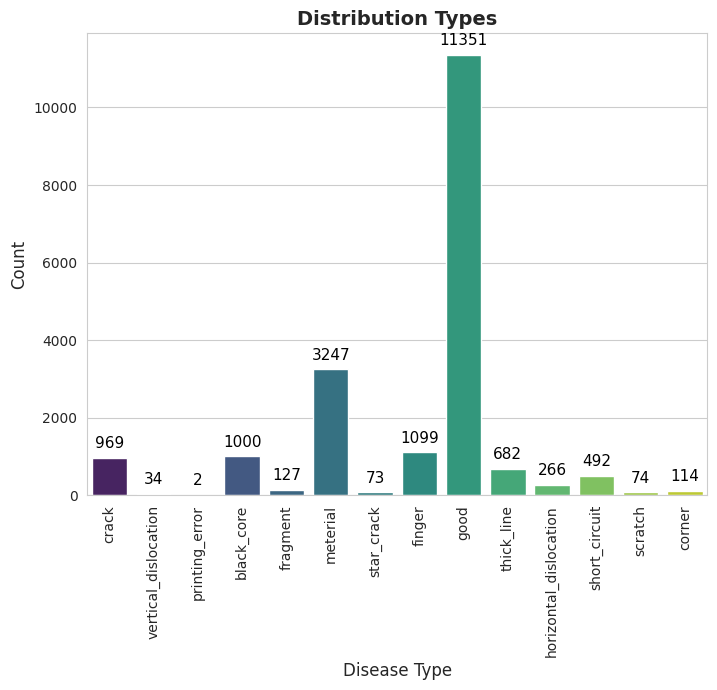

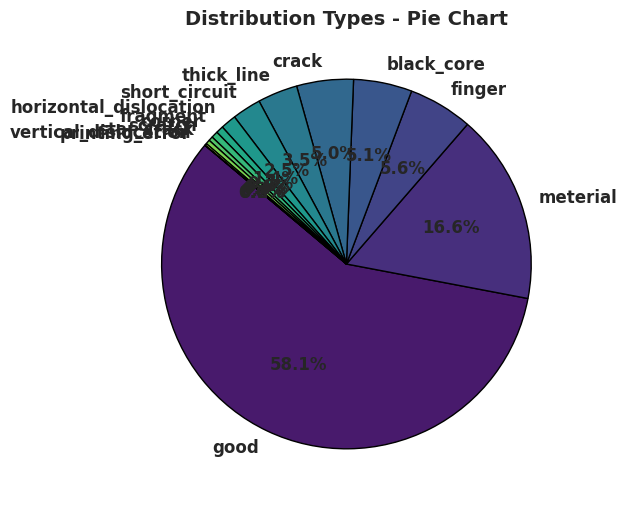

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(data=df, x="label", palette="viridis", ax=ax)

ax.set_title("Distribution Types", fontsize=14, fontweight='bold')
ax.set_xlabel("Disease Type", fontsize=12)
ax.set_ylabel("Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, color='black',
                xytext=(0, 5), textcoords='offset points')

plt.xticks(rotation = 90)
plt.show()

label_counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("viridis", len(label_counts))

ax.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%',
       startangle=140, colors=colors, textprops={'fontsize': 12, 'weight': 'bold'},
       wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax.set_title("Distribution Types - Pie Chart", fontsize=14, fontweight='bold')

plt.show()

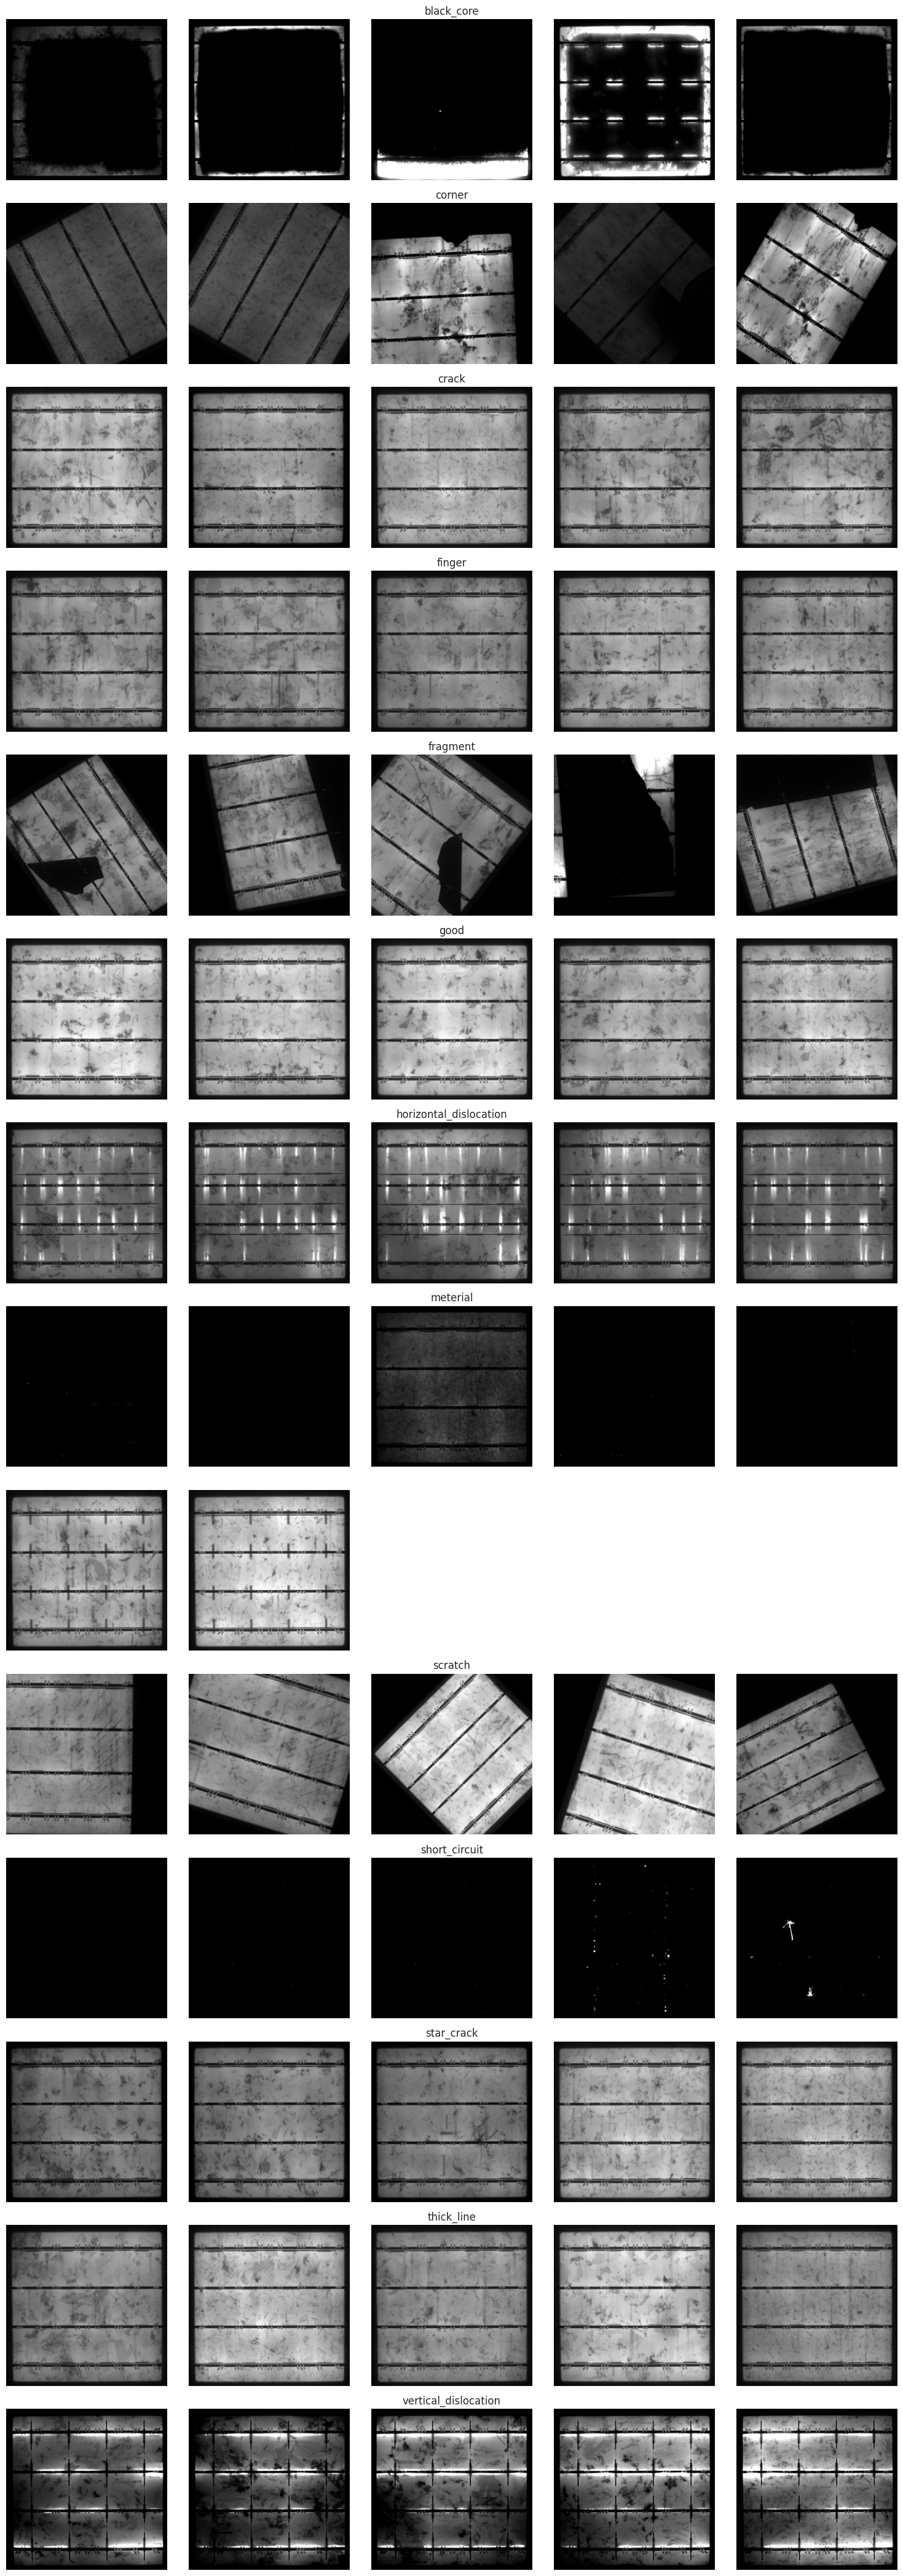

In [ ]:
import cv2

label_groups = {label: group.head(5)['image_path'].tolist()
                for label, group in df.groupby('label')}

num_labels = len(label_groups)

plt.figure(figsize=(15, 3 * num_labels))

for row, (label, images) in enumerate(label_groups.items()):
    for col, img_path in enumerate(images):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(num_labels, 5, row * 5 + col + 1)
        plt.imshow(img)
        plt.axis('off')
        if col == 2:
            plt.title(label, fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.utils import resample

max_count = df['label'].value_counts().max()

dfs = []
for category in df['label'].unique():
    class_subset = df[df['label'] == category]
    class_upsampled = resample(class_subset,
                               replace=True,
                               n_samples=max_count,
                               random_state=42)
    dfs.append(class_upsampled)

df_balanced = pd.concat(dfs).sample(frac=1, random_state=42).reset_index(drop=True)

In [ ]:
df = df_balanced

In [ ]:
df

,image_path,label
0,PV01/scratch/img003081_aug_6.jpg,scratch
1,PV01/crack/img002643.jpg,crack
2,PV01/meterial/img024745.jpg,meterial
3,PV01/horizontal_dislocation/img021285.jpg,horizontal_dislocation
4,PV01/vertical_dislocation/img021935.jpg,vertical_dislocation
...,...,...
158909,PV01/horizontal_dislocation/img021246.jpg,horizontal_dislocation
158910,PV01/thick_line/img002505.jpg,thick_line
158911,PV01/short_circuit/img022738.jpg,short_circuit
158912,PV01/scratch/img003229_aug_9.jpg,scratch


In [ ]:
# =========================
# Same-view KD (VGG16 teacher → StudentCNN student) + ANDROID EXPORTS
# =========================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silence TF if present

import json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Repro & device
# -----------------------------
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# EXACT class list (14 classes)
# -----------------------------
CLASS_NAMES = [
    'finger', 'black_core', 'crack', 'thick_line', 'short_circuit',
    'horizontal_dislocation', 'star_crack', 'vertical_dislocation',
    'fragment', 'corner', 'scratch', 'printing_error', 'good', 'meterial'
]
num_classes = len(CLASS_NAMES)  # 14
label2id = {c: i for i, c in enumerate(CLASS_NAMES)}
id2label = {i: c for i, c in enumerate(CLASS_NAMES)}

# -----------------------------
# Data prep (expects df with ['image_path','label'])
# -----------------------------
assert 'df' in globals(), "Provide df with columns ['image_path','label']"
assert {'image_path','label'}.issubset(df.columns), "df must have 'image_path' and 'label'"

# (safe) normalize any stray spaces/case in labels
def _norm_label(s): return str(s).strip().lower().replace(' ', '_')
df = df.copy()
df['label'] = df['label'].map(_norm_label)

# Drop non-image paths & .ipynb_checkpoints
VALID_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.gif'}
def is_valid_image_path(p):
    p = Path(str(p))
    return p.is_file() and p.suffix.lower() in VALID_EXT and ".ipynb_checkpoints" not in p.parts
df['image_path'] = df['image_path'].astype(str)
df = df[df['image_path'].apply(is_valid_image_path)].reset_index(drop=True)

unknown = set(pd.unique(df['label'])) - set(CLASS_NAMES)
assert not unknown, f"Unknown labels not in CLASS_NAMES: {unknown}"

# Stratified split 70/15/15
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
val_df,   test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

# -----------------------------
# Dataset (student-view only)
# -----------------------------
STUDENT_MEAN = [0.485, 0.456, 0.406]
STUDENT_STD  = [0.229, 0.224, 0.225]
IMG_SIZE = (224, 224)

transform_student_train = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),          # PV cells are symmetric
    transforms.RandomRotation(30),            # More rotation
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=STUDENT_MEAN, std=STUDENT_STD),
    transforms.RandomErasing(p=0.2),          # Simulate occlusion
])
transform_student_eval = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=STUDENT_MEAN, std=STUDENT_STD),
])

ImageFile.LOAD_TRUNCATED_IMAGES = True

class CustomImageDataset(Dataset):
    def __init__(self, dataframe, label_map, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.label_map = label_map
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['image_path']).convert('RGB')
        if self.transform is not None:
            img = self.transform(img)
        y = torch.tensor(self.label_map[row['label']], dtype=torch.long)
        return img, y

train_ds = CustomImageDataset(train_df, label2id, transform_student_train)
val_ds   = CustomImageDataset(val_df,   label2id, transform_student_eval)
test_ds  = CustomImageDataset(test_df,  label2id, transform_student_eval)

# -------- Weighted sampler for imbalance --------
train_labels_idx = [label2id[y] for y in train_df['label'].tolist()]
class_counts = np.bincount(train_labels_idx, minlength=num_classes).astype(np.float32)
class_weights_sampler = 1.0 / (class_counts + 1e-6)
sample_weights = [class_weights_sampler[i] for i in train_labels_idx]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

nw  = 2 if torch.cuda.is_available() else 0
pin = torch.cuda.is_available()
train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler, num_workers=nw, pin_memory=pin)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False,  num_workers=nw, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False,  num_workers=nw, pin_memory=pin)

# -----------------------------
# Teacher: VGG16 (torchvision) with new head (14)
# -----------------------------
teacher = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
in_features = teacher.classifier[6].in_features
teacher.classifier[6] = nn.Linear(in_features, num_classes)
teacher = teacher.to(device)

# ImageNet stats for VGG and student norm tensors
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1,3,1,1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1,3,1,1)
STU_MEAN_T = torch.tensor(STUDENT_MEAN, device=device).view(1,3,1,1)
STU_STD_T  = torch.tensor(STUDENT_STD,  device=device).view(1,3,1,1)

def vgg_logits_from_student(xs, training: bool = False):
    """
    Same-view: student-normalized xs -> denorm -> resize 224 -> VGG norm -> logits.
    training=True keeps autograd for teacher updates; False uses no_grad for speed.
    """
    xs_denorm = xs * STU_STD_T + STU_MEAN_T
    xs_224 = F.interpolate(xs_denorm, size=(224, 224), mode='bilinear', align_corners=False)
    xs_vgg = (xs_224 - IMNET_MEAN) / IMNET_STD
    if training:
        teacher.train()
        return teacher(xs_vgg)                # grad-enabled path
    else:
        teacher.eval()
        with torch.no_grad():
            return teacher(xs_vgg)            # no-grad path

# -----------------------------
# Student: CNN + RoPE + low-rank Gram (lighter)
# -----------------------------
class RotaryPositionEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len=4096):
        super().__init__()
        inv_freq = 1.0 / (10000 ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer("inv_freq", inv_freq)
        self.max_seq_len = max_seq_len
        t = torch.arange(self.max_seq_len)
        freqs = torch.einsum("i,j->ij", t, inv_freq)
        emb = torch.cat((freqs.cos(), freqs.sin()), dim=-1).float()
        self.register_buffer("cos_cached", emb[None, :, :])
        self.register_buffer("sin_cached", emb[None, :, :])
    def forward(self, x):  # [B,P,D]
        P = min(x.shape[1], self.max_seq_len)
        cos = self.cos_cached[:, :P, :].to(x.device)
        sin = self.sin_cached[:, :P, :].to(x.device)
        x = x[:, :P, :]
        return x * cos + torch.flip(x, dims=[-1]) * sin

class GramAnchoring(nn.Module):
    def __init__(self, embed_dim, reduced_dim=32):
        super().__init__()
        self.proj = nn.Linear(embed_dim, reduced_dim, bias=False)
    def forward(self, feats, teacher_feats=None):  # [B,P,D]
        if teacher_feats is None:
            teacher_feats = feats.detach()
        s = F.normalize(self.proj(feats), p=2, dim=-1)  # [B,P,d]
        t = F.normalize(self.proj(teacher_feats), p=2, dim=-1)
        gram_s = torch.bmm(s.transpose(1, 2), s)        # [B,d,d]
        gram_t = torch.bmm(t.transpose(1, 2), t)
        return gram_s, gram_t

class StudentCNN(nn.Module):
    def __init__(self, num_classes=num_classes, in_ch=3, embed_dim=64, token_side=128, gram_red=32):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, 64, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(64)
        self.conv2 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn2   = nn.BatchNorm2d(128)
        self.conv3 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn3   = nn.BatchNorm2d(256)
        self.conv4 = nn.Conv2d(256, embed_dim, 3, padding=1)  # projects 256 -> embed_dim
        self.bn4   = nn.BatchNorm2d(embed_dim)
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool2d(2, 2)

        with torch.no_grad():
            d = torch.zeros(1, in_ch, token_side, token_side)
            x = self.pool(self.relu(self.conv1(d)))
            x = self.pool(self.relu(self.conv2(x)))
            x = self.pool(self.relu(self.conv3(x)))
            x = self.relu(self.conv4(x))   # NOTE: no extra pool here, keep spatial size consistent with forward()
            patches = x.shape[2] * x.shape[3]

        self.rope = RotaryPositionEmbedding(embed_dim, max_seq_len=patches)
        self.gram = GramAnchoring(embed_dim, reduced_dim=gram_red)
        gram_size = gram_red * gram_red
        self.fc1  = nn.Linear(embed_dim + gram_size, 256)
        self.drop = nn.Dropout(0.5)
        self.fc2  = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.relu(self.conv4(x))       # NEW: project 256 -> embed_dim (64), matches __init__ probe
        B, D, H, W = x.shape                # D == embed_dim now
        tokens = x.permute(0,2,3,1).contiguous().view(B, H*W, D)  # [B,P,D]
        tokens = self.rope(tokens)
        gram_s, _ = self.gram(tokens)
        pooled = tokens.mean(dim=1)
        combined = torch.cat([pooled, gram_s.view(B, -1)], dim=1)
        h = self.drop(F.relu(self.fc1(combined)))
        return self.fc2(h)

student = StudentCNN(num_classes=num_classes, in_ch=3, embed_dim=64, token_side=224, gram_red=32).to(device)

# -----------------------------
# Loss (KD) and helpers
# -----------------------------
def kd_loss(student_logits, teacher_logits, labels, temperature=3.0, alpha=0.5,
            class_weights=None, label_smoothing=0.05):
    T = temperature
    with torch.no_grad():
        soft_t = F.softmax(teacher_logits / T, dim=-1)
    loss_kd = F.kl_div(F.log_softmax(student_logits / T, dim=-1),
                       soft_t, reduction='batchmean') * (T * T)
    loss_ce = F.cross_entropy(student_logits, labels,
                              weight=class_weights, label_smoothing=label_smoothing)
    return alpha * loss_ce + (1.0 - alpha) * loss_kd

def count_parameters(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# -----------------------------
# Class weights for CE (inverse freq)
# -----------------------------
counts = class_counts + 1e-6
cw = counts.sum() / (num_classes * counts)
class_weights_t = torch.tensor(cw, dtype=torch.float32, device=device)

# -----------------------------
# Teacher warm-up (head-only) → partial unfreeze (VGG)
# -----------------------------
# Freeze conv backbone first; train only classifier head
for p in teacher.features.parameters():
    p.requires_grad = False
for p in teacher.classifier.parameters():
    p.requires_grad = True

teacher_opt = optim.AdamW(filter(lambda p: p.requires_grad, teacher.parameters()), lr=1e-4, weight_decay=1e-4)
ce = nn.CrossEntropyLoss()

def train_teacher_epoch():
    teacher.train()
    tot, corr, n = 0.0, 0, 0
    for xs, ys in train_loader:
        xs, ys = xs.to(device), ys.to(device)
        teacher_opt.zero_grad(set_to_none=True)
        logits = vgg_logits_from_student(xs, training=True)  # grad-enabled
        loss = ce(logits, ys)
        loss.backward()
        teacher_opt.step()
        tot += loss.item() * xs.size(0)
        corr += (logits.argmax(1) == ys).sum().item()
        n += xs.size(0)
    return tot/n, corr/n

# Warm-up classifier
E_WARM = 20
for ep in range(E_WARM):
    tl, ta = train_teacher_epoch()
    print(f"[Teacher warmup] {ep+1}/{E_WARM}  loss={tl:.4f}  acc={ta:.4f}")

# Partial unfreeze: last conv block (features[24:]) + classifier
for p in teacher.parameters(): p.requires_grad = False
for p in teacher.features[24:].parameters(): p.requires_grad = True  # VGG16 last conv block
for p in teacher.classifier.parameters():     p.requires_grad = True

teacher_opt = optim.AdamW(filter(lambda p: p.requires_grad, teacher.parameters()), lr=5e-5, weight_decay=1e-4)
E_ADAPT = 50
for ep in range(E_ADAPT):
    tl, ta = train_teacher_epoch()
    print(f"[Teacher adapt ] {ep+1}/{E_ADAPT}  loss={tl:.4f}  acc={ta:.4f}")

teacher.eval()

# -----------------------------
# Student optimizer: cosine LR with warmup + grad clipping
# -----------------------------
student_opt = optim.AdamW(student.parameters(), lr=3e-4, weight_decay=1e-4)

def cosine_warmup_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * float(step) / float(max(1, warmup_steps))
    progress = float(step - warmup_steps) / float(max(1, total_steps - warmup_steps))
    return base_lr * 0.5 * (1.0 + np.cos(np.pi * progress))

EPOCHS_KD = 50
steps_per_epoch = len(train_loader)
total_steps = EPOCHS_KD * steps_per_epoch
warmup_steps = int(0.1 * total_steps)
base_lr = 3e-4

# -----------------------------
# KD Training (same-view) — uses a single history dict
# -----------------------------
def train_kd_PVAnamoly_VGG16_sameview1():
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    global_step = 0
    for ep in range(EPOCHS_KD):
        # Train
        student.train()
        tl_sum, correct, n = 0.0, 0, 0
        for xs, ys in train_loader:
            xs, ys = xs.to(device), ys.to(device)

            # update LR
            lr = cosine_warmup_lr(global_step, total_steps, warmup_steps, base_lr)
            for g in student_opt.param_groups: g['lr'] = lr
            global_step += 1

            student_opt.zero_grad(set_to_none=True)
            s_logits = student(xs)
            t_logits = vgg_logits_from_student(xs, training=False)  # SAME VIEW (no grad)
            loss = kd_loss(s_logits, t_logits, ys, temperature=3.0, alpha=0.3,
                           class_weights=class_weights_t, label_smoothing=0.05)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            student_opt.step()

            tl_sum += loss.item() * xs.size(0)
            correct += (s_logits.argmax(1) == ys).sum().item()
            n += xs.size(0)
        tr_loss, tr_acc = tl_sum/n, correct/n

        # Validate
        student.eval()
        vl_sum, vcorrect, vn = 0.0, 0, 0
        with torch.no_grad():
            for xs, ys in val_loader:
                xs, ys = xs.to(device), ys.to(device)
                s_logits = student(xs)
                t_logits = vgg_logits_from_student(xs, training=False)
                loss = kd_loss(s_logits, t_logits, ys, temperature=3.0, alpha=0.3,
                               class_weights=class_weights_t, label_smoothing=0.05)
                vl_sum += loss.item() * xs.size(0)
                vcorrect += (s_logits.argmax(1) == ys).sum().item()
                vn += xs.size(0)
        va_loss, va_acc = vl_sum/vn, vcorrect/vn

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        print(f"[KD same-view] Epoch {ep+1}/{EPOCHS_KD} | train {tr_loss:.4f}/{tr_acc:.4f} | val {va_loss:.4f}/{va_acc:.4f}")
    return history

history = train_kd_PVAnamoly_VGG16_sameview1()

# -----------------------------
# Plots
# -----------------------------
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history['train_loss'], label='Train'); plt.plot(history['val_loss'], label='Val')
plt.title('KD Loss'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history['train_acc'], label='Train'); plt.plot(history['val_acc'], label='Val')
plt.title('KD Accuracy'); plt.legend()
plt.tight_layout(); plt.show()

# -----------------------------
# Evaluation (teacher same-view & student)
# -----------------------------
def evaluate_student(model, loader, class_names, title='student'):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xs, ys in loader:
            xs, ys = xs.to(device), ys.to(device)
            logits = model(xs)
            preds.extend(logits.argmax(1).cpu().tolist())
            labels.extend(ys.cpu().tolist())
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))))
    plt.figure(figsize=(max(10,len(class_names)), max(8,len(class_names))))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {title}'); plt.ylabel('True'); plt.xlabel('Predicted'); plt.show()
    print(f'Classification Report - {title}:')
    print(classification_report(labels, preds, target_names=class_names, zero_division=0))
    return classification_report(labels, preds, target_names=class_names, zero_division=0, output_dict=True)

def evaluate_teacher_sameview(loader, class_names, title='teacher (same-view)'):
    teacher.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xs, ys in loader:
            xs, ys = xs.to(device), ys.to(device)
            logits = vgg_logits_from_student(xs, training=False)
            preds.extend(logits.argmax(1).cpu().tolist())
            labels.extend(ys.cpu().tolist())
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))))
    plt.figure(figsize=(max(10,len(class_names)), max(8,len(class_names))))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {title}'); plt.ylabel('True'); plt.xlabel('Predicted'); plt.show()
    print(f'Classification Report - {title}:')
    print(classification_report(labels, preds, target_names=class_names, zero_division=0))
    return classification_report(labels, preds, target_names=class_names, zero_division=0, output_dict=True)

teacher_report = evaluate_teacher_sameview(test_loader, CLASS_NAMES, 'teacher (same-view)')
student_report = evaluate_student(student, test_loader, CLASS_NAMES, 'student')

print("\nModel Parameter Comparison:")
print(f"Teacher (VGG16): {count_parameters(teacher):,}")
print(f"Student (CNN):   {count_parameters(student):,}")
print(f"Compression:     {count_parameters(teacher)/max(1,count_parameters(student)):.2f}x")
print("\nKnowledge Retention:")
print(f"Teacher acc: {teacher_report['accuracy']:.4f} | Student acc: {student_report['accuracy']:.4f} | "
      f"Retained: {(student_report['accuracy']/max(teacher_report['accuracy'],1e-9)*100):.2f}%")

[Teacher warmup] 1/20  loss=0.7916  acc=0.6772
[Teacher warmup] 2/20  loss=0.6674  acc=0.7245
[Teacher warmup] 3/20  loss=0.6425  acc=0.7360
[Teacher warmup] 4/20  loss=0.6192  acc=0.7449
[Teacher warmup] 5/20  loss=0.6095  acc=0.7482
[Teacher warmup] 6/20  loss=0.5919  acc=0.7553
[Teacher warmup] 7/20  loss=0.5877  acc=0.7574
[Teacher warmup] 8/20  loss=0.5859  acc=0.7585
[Teacher warmup] 9/20  loss=0.5837  acc=0.7578
[Teacher warmup] 10/20  loss=0.5744  acc=0.7632
[Teacher warmup] 11/20  loss=0.5731  acc=0.7630
[Teacher warmup] 12/20  loss=0.5681  acc=0.7669
[Teacher warmup] 13/20  loss=0.5651  acc=0.7677
[Teacher warmup] 14/20  loss=0.5595  acc=0.7692
[Teacher warmup] 15/20  loss=0.5622  acc=0.7680
[Teacher warmup] 16/20  loss=0.5574  acc=0.7710
[Teacher warmup] 17/20  loss=0.5533  acc=0.7719
[Teacher warmup] 18/20  loss=0.5483  acc=0.7749
[Teacher warmup] 19/20  loss=0.5473  acc=0.7756
[Teacher warmup] 20/20  loss=0.5505  acc=0.7728
[Teacher adapt ] 1/50  loss=0.5840  acc=0.7656
[T

In [ ]:
# =========================
# EXPORTS: Grad-CAM + .pth + Android (.ptl) ONLY
# =========================
from torch.utils.mobile_optimizer import optimize_for_mobile
import cv2

EXPORT_DIR = Path("export")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Sidecar metadata (kept in the .pth itself, no separate files)
ARTIFACTS = {
    "labels": CLASS_NAMES,
    "mean": STUDENT_MEAN,
    "std": STUDENT_STD,
    "img_size": list(IMG_SIZE),
    "arch": "StudentCNN",
}

# ---- A) PyTorch checkpoint (.pth) ----
torch.save({
    "state_dict": {k: v.cpu() for k, v in student.state_dict().items()},
    "meta": ARTIFACTS,
    "arch": "StudentCNN",
}, str(EXPORT_DIR / "student_fp32.pth"))

# ---- B) Android export (.ptl, PyTorch Mobile Lite) ----
student_cpu = student.eval().cpu()
example = torch.randn(1, 3, *IMG_SIZE)

try:
    ts = torch.jit.script(student_cpu)
except Exception as e:
    print("[Warn] torch.jit.script failed, falling back to trace:", e)
    ts = torch.jit.trace(student_cpu, example)

ts_mobile = optimize_for_mobile(ts)
ts_mobile._save_for_lite_interpreter(str(EXPORT_DIR / "student_mobile.ptl"))

print("Saved:", EXPORT_DIR / "student_fp32.pth")
print("Saved:", EXPORT_DIR / "student_mobile.ptl")

In [ ]:
# =========================
# GRAD-CAM: Teacher (VGG16) + Student, side by side
# =========================
import cv2

class GradCAM:
    """
    Generic Grad-CAM: hooks a target conv layer to capture activations + gradients,
    then produces a class-discriminative heatmap.
    """
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.fwd_handle = target_layer.register_forward_hook(self._save_activation)
        self.bwd_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove_hooks(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

    def generate(self, forward_fn, class_idx=None):
        """
        forward_fn: callable that takes no args and returns logits [1,num_classes]
                    (lets us route through vgg_logits_from_student for the teacher,
                     or student(x) directly for the student)
        """
        self.model.zero_grad()
        logits = forward_fn()
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        score = logits[:, class_idx].sum()
        score.backward(retain_graph=True)

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)        # [B,C,1,1]
        cam = (weights * self.activations).sum(dim=1, keepdim=True)    # [B,1,h,w]
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=IMG_SIZE, mode='bilinear', align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, logits.detach()


def overlay_gradcam_on_image(orig_pil_img, cam, alpha=0.4):
    img = np.array(orig_pil_img.resize(IMG_SIZE)).astype(np.float32) / 255.0
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    overlay = (1 - alpha) * img + alpha * heatmap
    overlay = np.clip(overlay, 0, 1)
    return Image.fromarray((overlay * 255).astype(np.uint8))


def get_teacher_target_layer():
    """Last Conv2d in VGG16's `features` block (same one that feeds the final pool)."""
    conv_layers = [m for m in teacher.features if isinstance(m, nn.Conv2d)]
    return conv_layers[-1]


def run_gradcam_comparison(df_row, class_names, save_path=None):
    """
    df_row: a row from test_df (or any df) with 'image_path' and 'label'.
    Produces a 1x3 figure: original | teacher Grad-CAM | student Grad-CAM.
    """
    pil_img = Image.open(df_row['image_path']).convert('RGB')
    true_label = df_row['label']

    # Student-normalized input tensor (this is the "same view" both models start from)
    xs = transform_student_eval(pil_img).unsqueeze(0).to(device)
    xs.requires_grad_(False)

    # ---- Student Grad-CAM ----
    student.eval()
    student_cam_extractor = GradCAM(student, target_layer=student.conv4)
    student_cam, student_pred_idx, _ = student_cam_extractor.generate(
        forward_fn=lambda: student(xs)
    )
    student_cam_extractor.remove_hooks()

    # ---- Teacher Grad-CAM (same-view: denorm -> resize -> VGG-norm, inside vgg_logits_from_student) ----
    teacher.eval()
    teacher_target_layer = get_teacher_target_layer()
    teacher_cam_extractor = GradCAM(teacher, target_layer=teacher_target_layer)
    teacher_cam, teacher_pred_idx, _ = teacher_cam_extractor.generate(
        forward_fn=lambda: vgg_logits_from_student(xs, training=True)  # training=True keeps grad path
    )
    teacher_cam_extractor.remove_hooks()

    student_overlay = overlay_gradcam_on_image(pil_img, student_cam)
    teacher_overlay = overlay_gradcam_on_image(pil_img, teacher_cam)

    student_pred_label = class_names[student_pred_idx]
    teacher_pred_label = class_names[teacher_pred_idx]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(pil_img.resize(IMG_SIZE))
    axes[0].set_title(f"Original\nTrue: {true_label}")
    axes[0].axis('off')

    axes[1].imshow(teacher_overlay)
    axes[1].set_title(f"Teacher (VGG16)\nPred: {teacher_pred_label}")
    axes[1].axis('off')

    axes[2].imshow(student_overlay)
    axes[2].set_title(f"Student (CNN)\nPred: {student_pred_label}")
    axes[2].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()

    return {
        "true_label": true_label,
        "teacher_pred": teacher_pred_label,
        "student_pred": student_pred_label,
        "teacher_overlay": teacher_overlay,
        "student_overlay": student_overlay,
    }


# ---- Run on a few test samples ----
GRADCAM_DIR = EXPORT_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

n_samples = min(5, len(test_df))
for i in range(n_samples):
    row = test_df.iloc[i]
    out_path = GRADCAM_DIR / f"gradcam_compare_{i}_{row['label']}.png"
    run_gradcam_comparison(row, CLASS_NAMES, save_path=str(out_path))

print("\nGrad-CAM comparisons saved to:", GRADCAM_DIR.resolve())